# Banking Credit Risk & Loan Portfolio Analytics

**Institution:** Northstar Bank (fictional)  
**Data:** Synthetic portfolio data generated for demonstration.  
**Tools:** Python, pandas, matplotlib, SQL.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
borrowers=pd.read_csv(ROOT/"data"/"borrowers.csv")
loans=pd.read_csv(ROOT/"data"/"loans.csv")
payments=pd.read_csv(ROOT/"data"/"loan_payments.csv")
df=loans.merge(borrowers,on="customer_id",how="left")


## 1. Data quality checks

In [2]:
for name, frame in {"borrowers":borrowers,"loans":loans,"payments":payments}.items():
    print(name, frame.shape, "duplicate rows:", frame.duplicated().sum())
    print(frame.isna().sum().to_dict())


borrowers (5000, 6) duplicate rows: 0
{'customer_id': 0, 'age': 0, 'annual_income': 0, 'employment_type': 0, 'region': 0, 'credit_score': 0}
loans (6200, 11) duplicate rows: 0
{'loan_id': 0, 'customer_id': 0, 'loan_type': 0, 'loan_amount': 0, 'annual_interest_rate': 0, 'term_months': 0, 'origination_date': 0, 'default_flag': 0, 'loan_status': 0, 'monthly_installment': 0, 'risk_band': 0}
payments (92941, 6) duplicate rows: 0
{'loan_id': 0, 'installment_number': 0, 'scheduled_amount': 0, 'late_payment_flag': 0, 'missed_payment_flag': 0, 'payment_date': 0}


## 2. Portfolio KPIs

In [3]:
kpis=pd.Series({
    "Loan count":len(df),
    "Unique borrowers":df.customer_id.nunique(),
    "Total exposure":df.loan_amount.sum(),
    "Default rate %":df.default_flag.mean()*100,
    "Average loan amount":df.loan_amount.mean(),
    "Late instalment rate %":payments.late_payment_flag.mean()*100,
    "Missed instalment rate %":payments.missed_payment_flag.mean()*100
})
display(kpis.round(2))


Loan count                  6.200000e+03
Unique borrowers            3.595000e+03
Total exposure              2.667008e+08
Default rate %              4.569000e+01
Average loan amount         4.301626e+04
Late instalment rate %      2.849000e+01
Missed instalment rate %    7.070000e+00
dtype: float64

## 3. Default rate by loan type

,loans,exposure,default_rate,default_rate_pct
loan_type,,,,
auto,1240,54773564.73,0.45,44.92
business,804,34699486.83,0.49,49.00
education,731,31225947.36,0.45,44.87
home,1228,51405696.21,0.44,44.30
personal,2197,94596104.95,0.46,45.97


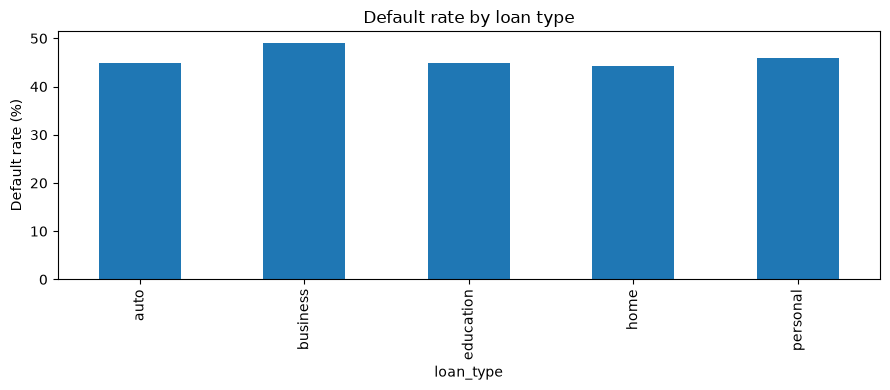

In [4]:
by_type=df.groupby("loan_type").agg(
    loans=("loan_id","count"), exposure=("loan_amount","sum"),
    default_rate=("default_flag","mean"))
by_type["default_rate_pct"]=100*by_type.default_rate
display(by_type.round(2))
by_type.default_rate_pct.plot(kind="bar",title="Default rate by loan type",figsize=(9,4))
plt.ylabel("Default rate (%)"); plt.tight_layout(); plt.show()


## 4. Default rate by credit score band

In [5]:
by_band=df.groupby("risk_band",observed=False).agg(
    loans=("loan_id","count"), default_rate=("default_flag","mean"))
by_band["default_rate_pct"]=100*by_band.default_rate
display(by_band.round(2))


,loans,default_rate,default_rate_pct
risk_band,,,
Fair,2137,0.48,48.34
Good,2440,0.45,45.12
Poor,301,0.51,50.83
Very Good,1322,0.41,41.30


## 5. Regional exposure

In [6]:
regional=df.groupby("region").agg(
    loans=("loan_id","count"), exposure=("loan_amount","sum"),
    default_rate=("default_flag","mean"))
regional["default_rate_pct"]=regional.default_rate*100
display(regional.round(2))


,loans,exposure,default_rate,default_rate_pct
region,,,,
Central,1304,55189031.96,0.45,45.17
East,1242,54245867.87,0.45,45.09
North,1169,51075330.72,0.44,43.88
South,1239,53616021.18,0.44,44.39
West,1246,52574548.35,0.50,49.84


## 6. Payment behaviour

In [7]:
payment_summary=payments.groupby("loan_id").agg(
    late_rate=("late_payment_flag","mean"),
    missed_rate=("missed_payment_flag","mean"))
payment_summary.describe().round(3)


,late_rate,missed_rate
count,6200.000,6200.000
mean,0.285,0.071
std,0.256,0.097
min,0.000,0.000
25%,0.056,0.000
50%,0.192,0.034
75%,0.500,0.120
max,1.000,0.750


## 7. Interpretation and limitations

- This is synthetic data; all observed relationships are constructed for demonstration.
- The default flag is a simulated outcome and does not establish causal relationships.
- Credit-score bands are descriptive, not a validated underwriting policy.
- No real-world credit decision should be made using this notebook or dashboard.